## Clusterings elegidos

Variables usadas:
    
    "Total Ingresos Anio Fiscal", "Total Beneficiarios", 
    "Dependencia de donativos", "Sustentabilidad"

(Sin costo de beneficiario)

k = 4

### Generar clusterings

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

df  = pd.read_excel("Identidad organizacional.xlsx")
k = 4

cols_log = ["Total Ingresos Anio Fiscal", "Total Beneficiarios"]
cols_otras = ["Dependencia de donativos", "Sustentabilidad"]

X = df[cols_log + cols_otras].copy()
X[cols_log] = np.log1p(X[cols_log].clip(lower=0))

# winsorizar
for c in X.columns:
    lo, hi = X[c].quantile([0.01, 0.99])
    X[c] = X[c].clip(lo, hi)

Xs = RobustScaler().fit_transform(X)


km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xs)
sil = silhouette_score(Xs, km.labels_, sample_size=10000, random_state=42)
print(k, round(km.inertia_), round(sil, 3))

4 49335 0.287


### Bubble charts

#### Gráfica 1 

Se diferencian los clusters 0, 2 y 3 por tamaño

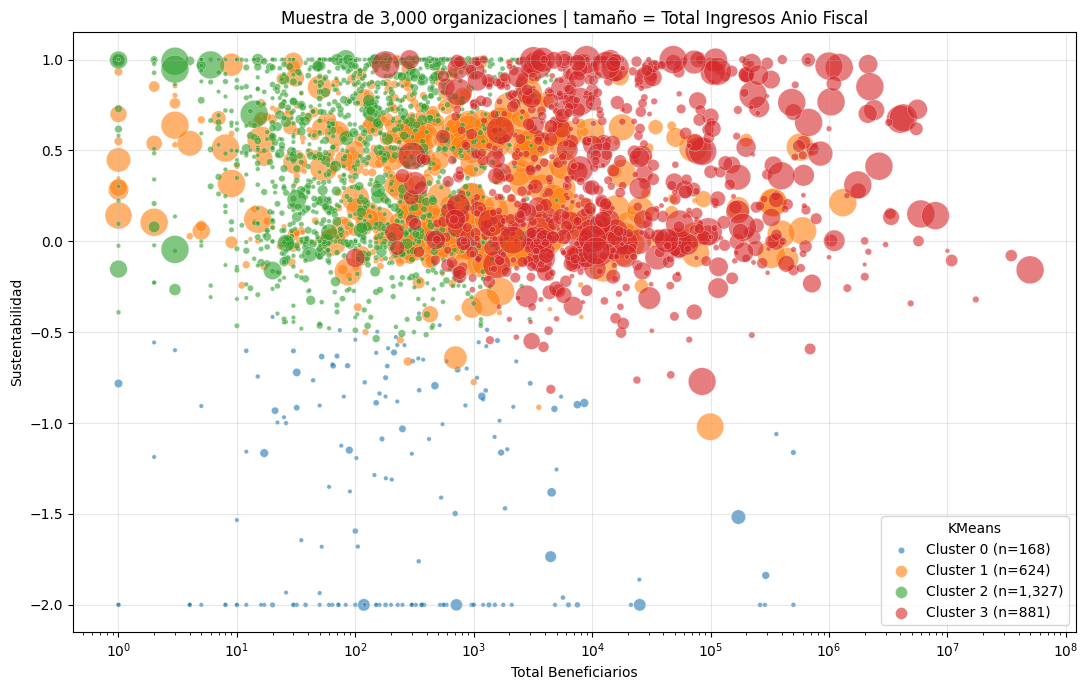

In [2]:
# ----------------------------------------------------------------------
# BUBBLE CHART: una burbuja por organización (muestra), color = cluster KMeans
# ----------------------------------------------------------------------

# ====== CAMBIA SOLO ESTAS LÍNEAS ======
VAR_X = "Total Beneficiarios"         # eje X
VAR_Y = "Sustentabilidad"   # eje Y
VAR_TAMANO = "Total Ingresos Anio Fiscal"  # tamaño de la burbuja
VAR_COLOR = None              # None = color por cluster; o una variable numérica (ej. "dependencia")
LOG_X = True                  # escala log en X (solo si todos los valores son > 0)
LOG_Y = False
N_MUESTRA = 3000              # nº de organizaciones a graficar
TAM_MIN, TAM_MAX = 10, 400    # rango del tamaño de burbuja
# ======================================

# Si km es el del último ciclo (k=9), reajusta con el k que elegiste:
# km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(Xs)
df["cluster_km"] = km.labels_

muestra = df.sample(n=min(N_MUESTRA, len(df)))

# Para escala log, se quitan valores <= 0
if LOG_X: muestra = muestra[muestra[VAR_X] > 0]
if LOG_Y: muestra = muestra[muestra[VAR_Y] > 0]

# Tamaño: se recorta al percentil 5-95 para que los outliers no aplasten al resto
if VAR_TAMANO:
    v = muestra[VAR_TAMANO]
    lo, hi = v.quantile([0.05, 0.95])
    norm = ((v.clip(lo, hi) - lo) / (hi - lo + 1e-9))
    tamanos = TAM_MIN + (TAM_MAX - TAM_MIN) * norm
else:
    tamanos = TAM_MIN * 3

fig, ax = plt.subplots(figsize=(11, 7))

if VAR_COLOR:
    sc = ax.scatter(muestra[VAR_X], muestra[VAR_Y], s=tamanos,
                    c=muestra[VAR_COLOR].clip(*muestra[VAR_COLOR].quantile([0.05, 0.95])),
                    cmap="viridis", alpha=0.6, edgecolors="white", linewidths=0.3)
    fig.colorbar(sc, label=VAR_COLOR)
else:
    cmap = plt.get_cmap("tab10")
    for i, c in enumerate(sorted(muestra["cluster_km"].unique())):
        m = muestra["cluster_km"] == c
        ax.scatter(muestra.loc[m, VAR_X], muestra.loc[m, VAR_Y],
                   s=tamanos[m] if VAR_TAMANO else tamanos,
                   color=cmap(i % 10), alpha=0.6, edgecolors="white", linewidths=0.3,
                   label=f"Cluster {c} (n={m.sum():,})")
    ax.legend(title="KMeans", markerscale=0.6, loc="best")

if LOG_X: ax.set_xscale("log")
if LOG_Y: ax.set_yscale("log")
ax.set_xlabel(VAR_X)
ax.set_ylabel(VAR_Y)
ax.set_title(f"Muestra de {len(muestra):,} organizaciones | tamaño = {VAR_TAMANO or 'fijo'}")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("bubble_organizaciones.png", dpi=150, bbox_inches="tight")
plt.show()

#### Gráfica 2

Se diferencia el cluster 1 de los demás por dependencia de donativos

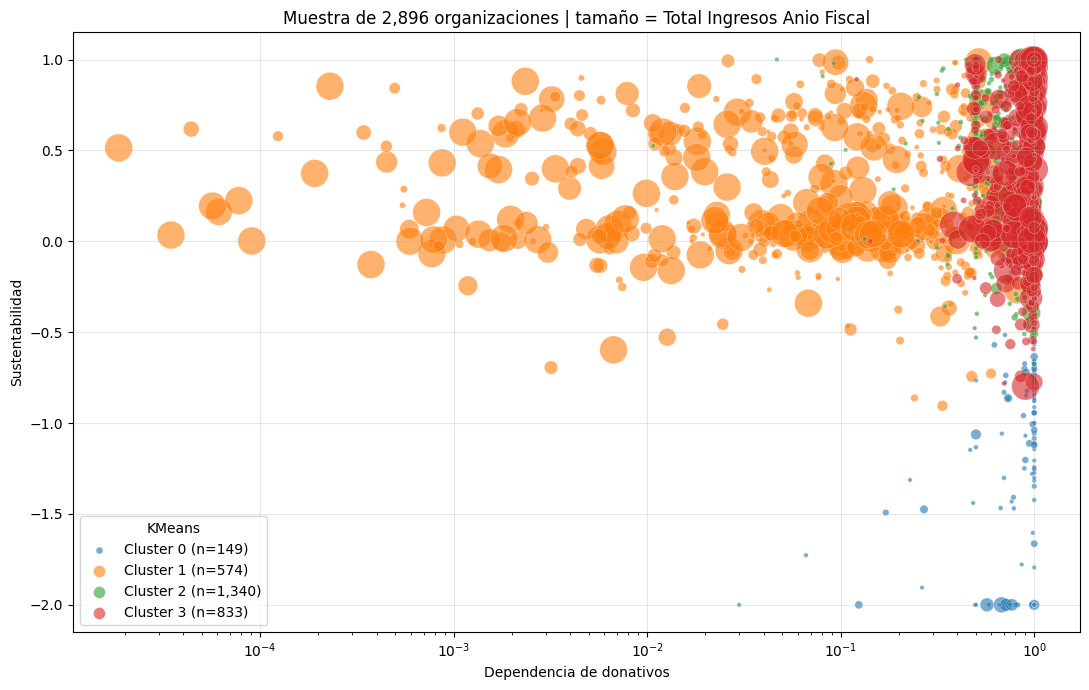

In [4]:
# ----------------------------------------------------------------------
# BUBBLE CHART: una burbuja por organización (muestra), color = cluster KMeans
# ----------------------------------------------------------------------

# ====== CAMBIA SOLO ESTAS LÍNEAS ======
VAR_X = "Dependencia de donativos"         # eje X
VAR_Y = "Sustentabilidad"   # eje Y
VAR_TAMANO = "Total Ingresos Anio Fiscal"  # tamaño de la burbuja
VAR_COLOR = None              # None = color por cluster; o una variable numérica (ej. "dependencia")
LOG_X = True                  # escala log en X (solo si todos los valores son > 0)
LOG_Y = False
N_MUESTRA = 3000              # nº de organizaciones a graficar
TAM_MIN, TAM_MAX = 10, 400    # rango del tamaño de burbuja
# ======================================

# Si km es el del último ciclo (k=9), reajusta con el k que elegiste:
# km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(Xs)
df["cluster_km"] = km.labels_

muestra = df.sample(n=min(N_MUESTRA, len(df)))

# Para escala log, se quitan valores <= 0
if LOG_X: muestra = muestra[muestra[VAR_X] > 0]
if LOG_Y: muestra = muestra[muestra[VAR_Y] > 0]

# Tamaño: se recorta al percentil 5-95 para que los outliers no aplasten al resto
if VAR_TAMANO:
    v = muestra[VAR_TAMANO]
    lo, hi = v.quantile([0.05, 0.95])
    norm = ((v.clip(lo, hi) - lo) / (hi - lo + 1e-9))
    tamanos = TAM_MIN + (TAM_MAX - TAM_MIN) * norm
else:
    tamanos = TAM_MIN * 3

fig, ax = plt.subplots(figsize=(11, 7))

if VAR_COLOR:
    sc = ax.scatter(muestra[VAR_X], muestra[VAR_Y], s=tamanos,
                    c=muestra[VAR_COLOR].clip(*muestra[VAR_COLOR].quantile([0.05, 0.95])),
                    cmap="viridis", alpha=0.6, edgecolors="white", linewidths=0.3)
    fig.colorbar(sc, label=VAR_COLOR)
else:
    cmap = plt.get_cmap("tab10")
    for i, c in enumerate(sorted(muestra["cluster_km"].unique())):
        m = muestra["cluster_km"] == c
        ax.scatter(muestra.loc[m, VAR_X], muestra.loc[m, VAR_Y],
                   s=tamanos[m] if VAR_TAMANO else tamanos,
                   color=cmap(i % 10), alpha=0.6, edgecolors="white", linewidths=0.3,
                   label=f"Cluster {c} (n={m.sum():,})")
    ax.legend(title="KMeans", markerscale=0.6, loc="best")

if LOG_X: ax.set_xscale("log")
if LOG_Y: ax.set_yscale("log")
ax.set_xlabel(VAR_X)
ax.set_ylabel(VAR_Y)
ax.set_title(f"Muestra de {len(muestra):,} organizaciones | tamaño = {VAR_TAMANO or 'fijo'}")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("bubble_organizaciones.png", dpi=150, bbox_inches="tight")
plt.show()